In [ ]:
import requests
import pandas as pd

# Thiết lập thông số lấy dữ liệu (Tọa độ Đà Lạt)
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 11.9464,    # Vĩ độ Đà Lạt
    "longitude": 108.4419,  # Kinh độ Đà Lạt
    "start_date": "2023-01-01",
    "end_date": "2023-12-31",
    "hourly": "temperature_2m,relative_humidity_2m,precipitation", # Nhiệt độ, độ ẩm, lượng mưa
    "timezone": "Asia/Ho_Chi_Minh"
}

# Gọi API và lấy dữ liệu JSON
print("Đang tải dữ liệu từ Open-Meteo...")
response = requests.get(url, params=params)
data = response.json()

# Chuyển đổi dữ liệu JSON thành DataFrame (dạng bảng)
df = pd.DataFrame(data['hourly'])

# Đổi tên cột 
df.rename(columns={
    'temperature_2m': 'nhiet_do',
    'relative_humidity_2m': 'do_am_kk',
    'precipitation': 'luong_mua'
}, inplace=True)

# Chuyển cột thời gian sang định dạng chuẩn datetime
df['time'] = pd.to_datetime(df['time'])

# Lưu ra file CSV
file_name = "weather_dalat_2023.csv"
df.to_csv(file_name, index=False)

print(f"Xong! Đã lưu dữ liệu vào file {file_name}")
print(df.head()) # In thử 5 dòng đầu

Đang tải dữ liệu từ Open-Meteo...
Xong! Đã lưu dữ liệu vào file weather_dalat_2023.csv
                 time  nhiet_do  do_am_kk  luong_mua
0 2023-01-01 00:00:00      12.7        97        0.1
1 2023-01-01 01:00:00      12.4        98        0.0
2 2023-01-01 02:00:00      12.7        98        0.0
3 2023-01-01 03:00:00      13.0        97        0.0
4 2023-01-01 04:00:00      13.0        97        0.0


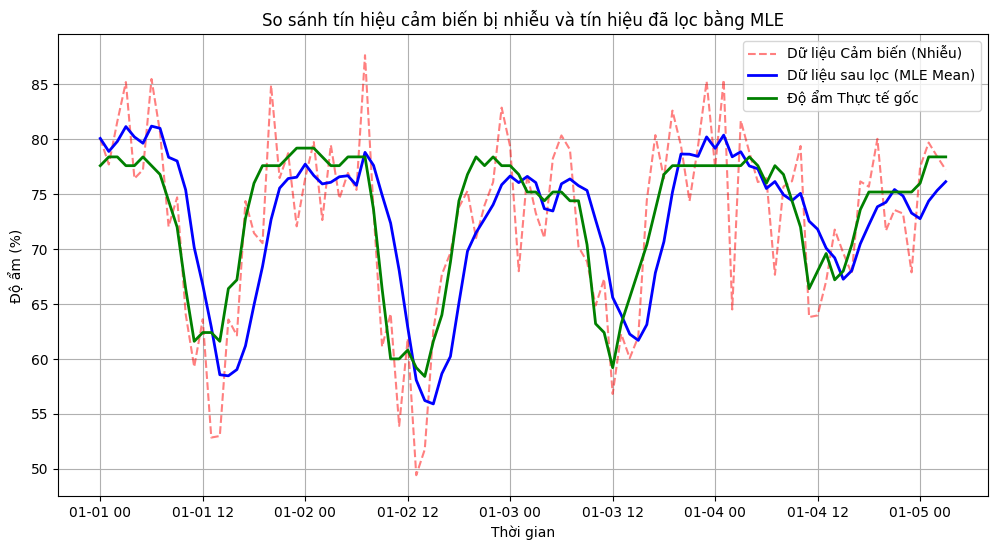

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Giả lập: Tạo ra độ ẩm đất thực tế (ví dụ bằng 80% độ ẩm không khí)
df['do_am_dat_thuc'] = df['do_am_kk'] * 0.8

# 1. THÊM NHIỄU CẢM BIẾN (Gaussian Noise)
# Giả sử cảm biến bị nhiễu theo phân phối chuẩn Gaussian(mu=0, sigma=5%)
np.random.seed(42) # Cố định seed để nhiễu không đổi mỗi lần chạy
noise = np.random.normal(loc=0, scale=5, size=len(df))
df['sensor_do_am'] = df['do_am_dat_thuc'] + noise

# 2. ÁP DỤNG GAUSSIAN MLE ĐỂ LỌC NHIỄU
# Ta dùng một "cửa sổ trượt" (rolling window) gồm 5 giờ liên tiếp (n=5)
window_size = 5

# a) Tính MLE cho Kỳ vọng (Mean): mu_MLE = 1/n * sum(x)
df['mle_mu_do_am'] = df['sensor_do_am'].rolling(window=window_size, min_periods=1).mean()

# b) Tính MLE cho Phương sai (Variance): sigma^2_MLE = 1/n * sum(x - mu)^2
# Lưu ý cực hay: ddof=0 trong pandas nghĩa là chia cho n (đúng chuẩn MLE),
# nếu ddof=1 là chia cho (n-1) (sample variance).
df['mle_sigma2_do_am'] = df['sensor_do_am'].rolling(window=window_size, min_periods=1).var(ddof=0)

# 3. TRỰC QUAN HÓA (Vẽ biểu đồ 100 giờ đầu tiên để thấy kết quả)
plt.figure(figsize=(12, 6))
subset = df.iloc[:100] # Chỉ lấy 100 dòng đầu cho dễ nhìn

plt.plot(subset['time'], subset['sensor_do_am'], label='Dữ liệu Cảm biến (Nhiễu)', color='red', alpha=0.5, linestyle='--')
plt.plot(subset['time'], subset['mle_mu_do_am'], label='Dữ liệu sau lọc (MLE Mean)', color='blue', linewidth=2)
plt.plot(subset['time'], subset['do_am_dat_thuc'], label='Độ ẩm Thực tế gốc', color='green', linewidth=2)

plt.title('So sánh tín hiệu cảm biến bị nhiễu và tín hiệu đã lọc bằng MLE')
plt.xlabel('Thời gian')
plt.ylabel('Độ ẩm (%)')
plt.legend()
plt.grid(True)
plt.show()

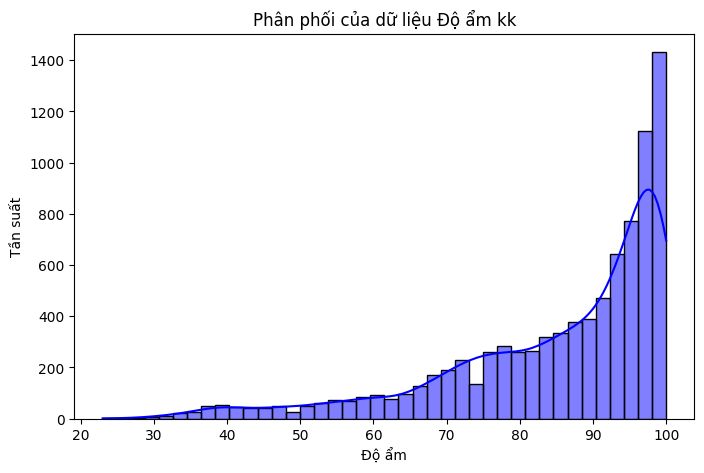

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.histplot(df['do_am_kk'], kde=True, color='blue')
plt.title('Phân phối của dữ liệu Độ ẩm kk')
plt.xlabel('Độ ẩm')
plt.ylabel('Tần suất')
plt.show()

In [ ]:
# 1. TẠO CỘT MỤC TIÊU (DÁN NHÃN - LABELING)
# Giả sử quy tắc của kỹ sư nông nghiệp:
# "Nếu độ ẩm đất (đã lọc MLE) dưới 65% VÀ trời không mưa (< 0.1mm) thì BẬT BƠM (1), ngược lại TẮT (0)"
df['can_tuoi_nuoc'] = np.where((df['mle_mu_do_am'] < 65) & (df['luong_mua'] < 0.1), 1, 0)

# 2. TẠO ĐẶC TRƯNG MỚI (FEATURE ENGINEERING)
# Tách giờ trong ngày từ cột thời gian (vì trưa nắng thì đất bốc hơi nhanh hơn đêm)
df['gio_trong_ngay'] = df['time'].dt.hour

# (Tùy chọn) Thêm đặc trưng độ biến động: Nếu phương sai MLE quá cao, có thể đang có nhiễu bất thường
df['muc_do_bien_dong'] = df['mle_sigma2_do_am']

# 3. LỌC LẠI BẢNG DỮ LIỆU CHUẨN (TABULAR DATASET) ĐỂ ĐƯA VÀO ML
# Loại bỏ các dòng bị NaN (do lúc tính MLE ở 5 giờ đầu tiên chưa đủ dữ liệu)
df = df.dropna()

# Chốt lại các cột đầu vào (X) và đầu ra (y)
features = ['nhiet_do', 'do_am_kk', 'mle_mu_do_am', 'luong_mua', 'gio_trong_ngay', 'muc_do_bien_dong']
target = 'can_tuoi_nuoc'

X = df[features]
y = df[target]

# Kiểm tra xem dữ liệu có bị mất cân bằng không (số lần bật bơm vs tắt bơm)
print("Số lượng nhãn 0 (Tắt) và 1 (Bật):")
print(y.value_counts())

# In thử 5 dòng của tập dữ liệu cuối cùng
print("\nTập dữ liệu chuẩn bị đưa vào huấn luyện:")
print(X.head())

Số lượng nhãn 0 (Tắt) và 1 (Bật):
can_tuoi_nuoc
0    7092
1    1668
Name: count, dtype: int64

Tập dữ liệu chuẩn bị đưa vào huấn luyện:
   nhiet_do  do_am_kk  mle_mu_do_am  luong_mua  gio_trong_ngay  \
0      12.7        97     80.083571        0.1               0   
1      12.4        98     78.896125        0.0               1   
2      12.7        98     79.810231        0.0               2   
3      13.0        97     81.161460        0.0               3   
4      13.0        97     80.215015        0.0               4   

   muc_do_bien_dong  
0          0.000000  
1          1.410028  
2          2.611199  
3          7.435864  
4          9.531727  


Kích thước tập Train: 7008 mẫu
Kích thước tập Test: 1752 mẫu

--- ĐÁNH GIÁ MÔ HÌNH: LOGISTIC REGRESSION ---
Độ chính xác (Accuracy): 94.18%

              precision    recall  f1-score   support

           0       0.95      0.98      0.96      1418
           1       0.91      0.77      0.83       334

    accuracy                           0.94      1752
   macro avg       0.93      0.87      0.90      1752
weighted avg       0.94      0.94      0.94      1752

--- ĐÁNH GIÁ MÔ HÌNH: RANDOM FOREST ---
Độ chính xác (Accuracy): 99.94%

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1418
           1       1.00      1.00      1.00       334

    accuracy                           1.00      1752
   macro avg       1.00      1.00      1.00      1752
weighted avg       1.00      1.00      1.00      1752



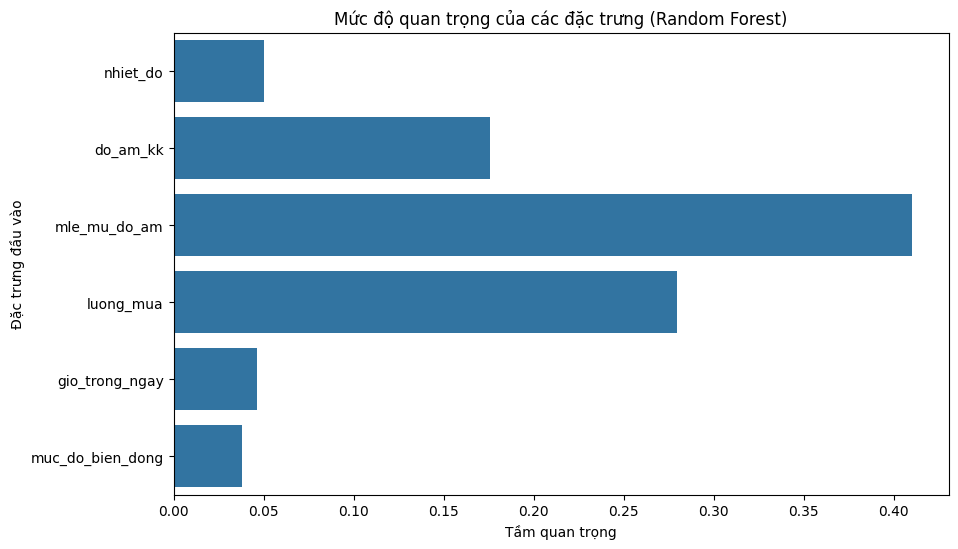

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import seaborn as sns

# 1. CHIA TẬP DỮ LIỆU (TRAIN / TEST)
# Chia 80% dữ liệu để huấn luyện (học), 20% để kiểm thử (thi)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Kích thước tập Train: {X_train.shape[0]} mẫu")
print(f"Kích thước tập Test: {X_test.shape[0]} mẫu\n")

# 2. HUẤN LUYỆN MÔ HÌNH 1: LOGISTIC REGRESSION (Mô hình cơ bản)
print("--- ĐÁNH GIÁ MÔ HÌNH: LOGISTIC REGRESSION ---")
model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train, y_train) # Quá trình học
y_pred_lr = model_lr.predict(X_test) # Quá trình dự đoán
print(f"Độ chính xác (Accuracy): {accuracy_score(y_test, y_pred_lr) * 100:.2f}%\n")
print(classification_report(y_test, y_pred_lr))

# 3. HUẤN LUYỆN MÔ HÌNH 2: RANDOM FOREST (Mô hình nâng cao)
print("--- ĐÁNH GIÁ MÔ HÌNH: RANDOM FOREST ---")
model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train) # Quá trình học
y_pred_rf = model_rf.predict(X_test) # Quá trình dự đoán
print(f"Độ chính xác (Accuracy): {accuracy_score(y_test, y_pred_rf) * 100:.2f}%\n")
print(classification_report(y_test, y_pred_rf))

# 4. TRỰC QUAN HÓA FEATURE IMPORTANCE (Đặc trưng nào quan trọng nhất?)
plt.figure(figsize=(10, 6))
feature_importances = model_rf.feature_importances_
sns.barplot(x=feature_importances, y=features)
plt.title("Mức độ quan trọng của các đặc trưng (Random Forest)")
plt.xlabel("Tầm quan trọng")
plt.ylabel("Đặc trưng đầu vào")
plt.show()